# Explorador interactivo de imputaciones



In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, clear_output

try:
    import ipywidgets as widgets
    WIDGETS_DISPONIBLES = True
except ImportError:
    WIDGETS_DISPONIBLES = False

plt.rcParams.update({'figure.figsize': (11, 4.5), 'axes.grid': True, 'grid.alpha': .22})

# Admite ejecución desde raíz o desde subcarpeta notebooks/.
def encontrar_raiz():
    here = Path.cwd().resolve()
    for p in (here, *here.parents):
        if (p / 'normalizacion/matriz_ishii_R.csv').is_file() and (p / 'resultados_estudio/validacion/predicciones.csv').is_file():
            return p
    raise FileNotFoundError('No se encontró la raíz IPre. Abre el notebook desde el repositorio con los resultados_estudio existentes.')

ROOT = encontrar_raiz()
RES = ROOT / 'resultados_estudio'
print('Proyecto:', ROOT)
print('Resultados:', RES)

Proyecto: C:\Users\HP 440 G10\OneDrive\Escritorio\IPre_PedroSaa
Resultados: C:\Users\HP 440 G10\OneDrive\Escritorio\IPre_PedroSaa\resultados_estudio


## 1 · Datos de origen, máscaras y resultados existentes

Se comprueba la correspondencia de metabolitos, muestras, la conversión R↔mM y la estructura de los archivos. Ninguna función ejecuta `to_csv`, `savefig` o escribe archivos.

In [2]:
def leer_csv(ruta, index_col=None):
    if not ruta.is_file():
        raise FileNotFoundError(f'Falta el archivo requerido: {ruta}')
    return pd.read_csv(ruta, index_col=index_col)

ish_R = leer_csv(ROOT/'normalizacion/matriz_ishii_R.csv', index_col=0)
ish_mM = leer_csv(ROOT/'normalizacion/matriz_ishii_mM.csv', index_col=0)
refs = leer_csv(ROOT/'normalizacion/referencias_glucosa.csv', index_col=0)['value_mM']
pred = leer_csv(RES/'validacion/predicciones.csv')
real = leer_csv(RES/'imputacion/candidatos_y_soporte.csv')
verdades = leer_csv(ROOT/'validacion_comun/verdades_ishii.csv')
with (ROOT/'validacion_comun/masks.json').open(encoding='utf-8') as f:
    masks = json.load(f)

assert ish_R.index.is_unique and ish_R.columns.is_unique
assert ish_R.index.equals(ish_mM.index) and ish_R.columns.equals(ish_mM.columns)
assert np.allclose(ish_R.mul(refs).to_numpy(), ish_mM.to_numpy(), equal_nan=True)
assert {'trial_id','sample_id','metabolite_id','experiment','scenario','method','truth_R','truth_mM','estimate_R','estimate_mM','support'}.issubset(pred.columns)
assert {'sample_id','metabolite_id','scenario','method','estimate_R','estimate_mM','support'}.issubset(real.columns)
assert {'trial_id','sample_id','metabolite_id','truth_R','truth_mM'}.issubset(verdades.columns)
assert len(masks['trials']) == len({t['trial_id'] for t in masks['trials']})
assert not pred.duplicated(['trial_id','metabolite_id','scenario','method']).any()
assert not real.duplicated(['sample_id','metabolite_id','scenario','method']).any()

METABOLITOS = list(ish_R.columns)
METODOS = ['SimpleImputer','KNNImputer','IterativeImputer']
ESCENARIOS = ['ishii','ishii_mmc2']
EXPERIMENTOS = sorted(pred['experiment'].dropna().unique())
POLITICAS = ['available','supported_plus_baseline']
TRIALS = {t['trial_id']: t for t in masks['trials']}
print('Muestras Ishii:', len(ish_R), '| Metabolitos:', len(METABOLITOS))
print('Ensayos oficiales:', len(TRIALS), '| Casos con verdad:', len(verdades))
print('Métodos:', ', '.join(METODOS), '| Escenarios:', ', '.join(ESCENARIOS))
display(ish_mM.notna().sum().rename('n medidos').to_frame().T)

Muestras Ishii: 30 | Metabolitos: 7
Ensayos oficiales: 299 | Casos con verdad: 435
Métodos: SimpleImputer, KNNImputer, IterativeImputer | Escenarios: ishii, ishii_mmc2


,fum[c],pep[c],s7p[c],succ[c],pyr[c],akg[c],cit[c]
n medidos,23,22,29,27,14,11,12


## 2 · Estadísticos descriptivos

Reporta `n`, media, mediana, desviación estándar muestral (ddof=1), Q1, Q3, IQR, mínimo, máximo, varianza y CV. Si la media es prácticamente cero o hay menos de dos datos, el CV o la desviación no se consideran interpretables.

En la comparación de **imputación real**, el conjunto «antes» son los valores efectivamente medidos de Ishii; «después» son esos mismos valores más las predicciones seleccionadas para las celdas originalmente faltantes. **No equivale a demostrar que la distribución verdadera haya sido recuperada.**

In [3]:
def descriptivos(serie, epsilon=1e-12):
    s = pd.to_numeric(serie, errors='coerce').dropna()
    n = len(s)
    mu = float(s.mean()) if n else np.nan
    sd = float(s.std(ddof=1)) if n >= 2 else np.nan
    q1, q3 = (float(s.quantile(.25)),float(s.quantile(.75))) if n else (np.nan,np.nan)
    return pd.Series({
        'n': n, 'media':mu, 'mediana':float(s.median()) if n else np.nan,
        's':sd, 'varianza':sd**2 if n>=2 else np.nan,
        'Q1':q1,'Q3':q3,'IQR':q3-q1,
        'min':float(s.min()) if n else np.nan,
        'max':float(s.max()) if n else np.nan,
        'CV (%)':100*sd/mu if n>=2 and mu>epsilon else np.nan
    })

def aceptada(df, politica):
    ok = np.isfinite(pd.to_numeric(df['estimate_R'], errors='coerce').to_numpy())
    if politica == 'supported_plus_baseline':
        ok &= ((df.method == 'SimpleImputer') | (df.support == 'supported')).to_numpy()
    return pd.Series(ok, index=df.index)

def matriz_real(metodo, escenario, politica):
    x = ish_mM.copy()
    sub = real[(real.method==metodo) & (real.scenario==escenario)].copy()
    seleccionadas = sub.loc[aceptada(sub, politica)]
    for v in seleccionadas.itertuples():
        assert pd.isna(x.loc[v.sample_id, v.metabolite_id]), 'Predicción sobre medición original'
        x.loc[v.sample_id, v.metabolite_id] = v.estimate_mM
    obs = ish_mM.notna()
    assert np.array_equal(x.to_numpy()[obs],ish_mM.to_numpy()[obs]), 'Se alteraron observaciones'
    return x, sub, seleccionadas

def tabla_antes_despues(a,b):
    df=pd.concat([descriptivos(a).rename('Antes'),descriptivos(b).rename('Después')],axis=1)
    df['Cambio absoluto'] = df['Después']-df['Antes']
    df['Cambio (%)'] = np.where(np.isfinite(df['Antes']) & (df['Antes']!=0),100*df['Cambio absoluto']/df['Antes'],np.nan)
    return df

## 3 · Panel interactivo

**Gráfico principal:** para cada caso de validación, se muestra el valor original de Ishii que se ocultó artificialmente y la predicción del método seleccionado en la **misma posición**, unidos por una línea que permite ver el error. Las muestras repetidas en distintos ensayos se distinguen por su identificador de ensayo y **no** representan réplicas biológicas independientes.

El diagrama real-vs-predicho complementa la comparación. Más abajo, y claramente separado, se visualiza la imputación de **faltantes reales**: allí no hay verdad experimental para evaluar exactitud.

La política `available` acepta candidatos numéricos finitos; `supported_plus_baseline` exige `supported`, salvo `SimpleImputer` como referencia. Se muestran los candidatos rechazados sin confundirlos con estimaciones aceptadas.


In [4]:
def _comparacion_pareada_por_muestra(df, unidad, politica):
    """Una pareja por caso de validación: verdad original y predicción del mismo caso."""
    verdad = 'truth_mM' if unidad == 'mM' else 'truth_R'
    estim = 'estimate_mM' if unidad == 'mM' else 'estimate_R'
    x = df.copy()
    x['ok'] = aceptada(x, politica)
    x[verdad] = pd.to_numeric(x[verdad], errors='coerce')
    x[estim] = pd.to_numeric(x[estim], errors='coerce')
    x = x.loc[np.isfinite(x[verdad])].sort_values(['sample_id', 'trial_id']).reset_index(drop=True)
    if x.empty:
        display(Markdown('No hay valores experimentales de referencia para esta selección.'))
        return
    # Repeticiones de una misma muestra en ensayos distintos son casos, no réplicas biológicas.
    rep = x.groupby('sample_id').size()
    labels = [f'{r.sample_id} · {r.trial_id}' if rep.loc[r.sample_id] > 1 else str(r.sample_id)
              for r in x.itertuples()]
    xx = np.arange(len(x))
    fig, ax = plt.subplots(figsize=(max(10, min(24, len(x)*0.65)), 4.8))
    shown = {'accepted':False, 'rejected':False}
    for j, r in x.iterrows():
        val = r[estim]
        if not np.isfinite(val):
            continue
        yes = bool(r['ok'])
        col = 'tab:blue' if yes else 'tab:orange'
        ax.plot([j,j], [r[verdad], val], color=col, alpha=.45, lw=1.4, zorder=1)
    ax.scatter(xx, x[verdad], color='tab:green', s=45, marker='o', zorder=3,
               label='Medición original (ocultada en validación)')
    for accepted, color, marker, key, name in [(True,'tab:blue','D','accepted','Imputación aceptada'),
                                                 (False,'tab:orange','x','rejected','Candidato no aceptado')]:
        mask = x['ok'].eq(accepted) & np.isfinite(x[estim])
        if mask.any():
            ax.scatter(xx[mask], x.loc[mask,estim], color=color, marker=marker, s=53,
                       zorder=4, label=name)
    missing = ~np.isfinite(x[estim])
    if missing.any():
        ax.scatter(xx[missing],x.loc[missing,verdad], s=110, marker='o',
                   facecolors='none', edgecolors='tab:red', linewidths=1.5,
                   label='Sin predicción numérica')
    ax.set(xticks=xx, xticklabels=labels, ylabel=f'Concentración ({unidad})',
           xlabel='Muestra / ensayo (cada posición corresponde a un caso de validación)',
           title='Validación enmascarada: valor real vs valor imputado')
    ax.tick_params(axis='x', rotation=90)
    ax.legend(loc='best')
    plt.tight_layout(); plt.show()

def _scatter_validacion(df, unidad):
    verdad='truth_mM' if unidad=='mM' else 'truth_R'
    estim='estimate_mM' if unidad=='mM' else 'estimate_R'
    x=df.copy()
    x['ok']=aceptada(x, POLITICA_ACTUAL)
    fig,ax=plt.subplots(figsize=(7,5))
    for label,sel,color,marker in [('Aceptadas',x['ok'],'tab:green','o'),('No aceptadas',~x['ok'],'tab:orange','x')]:
        p=x.loc[sel & np.isfinite(x[estim]) & np.isfinite(x[verdad])]
        if len(p):ax.scatter(p[verdad],p[estim],label=f'{label} (n={len(p)})',alpha=.75,c=color,marker=marker)
    numbers=np.r_[x[verdad].to_numpy(float),x[estim].to_numpy(float)]
    numbers=numbers[np.isfinite(numbers)]
    if len(numbers):
        lo,hi=min(numbers),max(numbers)
        margin=max((hi-lo)*.05,1e-10)
        ax.plot([lo-margin,hi+margin],[lo-margin,hi+margin],ls='--',c='gray',lw=1,label='Identidad')
    ax.set(xlabel=f'Real ({unidad})',ylabel=f'Predicho ({unidad})',title='Validación: valor experimental vs predicción')
    ax.legend();plt.show()

def _puntos_por_muestra(met, unidad, filas=None):
    base=ish_mM if unidad=='mM' else ish_R
    fig,ax=plt.subplots(figsize=(12,3.7))
    xx=np.arange(len(base));col=base[met]
    ax.scatter(xx[col.notna()],col[col.notna()],color='tab:green',label='Medido originalmente',zorder=3)
    ax.scatter(xx[col.isna()],[0]*int(col.isna().sum()),marker='|',color='gray',label='Ausencia real (marca en eje)')
    if filas is not None and len(filas):
        for estado,color,marker in [(True,'tab:blue','D'),(False,'tab:orange','x')]:
            g=filas.loc[filas['ok']==estado]
            idx=base.index.get_indexer(g.sample_id)
            val=g['estimate_mM' if unidad=='mM' else 'estimate_R'].to_numpy(float)
            mask=(idx>=0) & np.isfinite(val)
            if mask.any():ax.scatter(idx[mask],val[mask],color=color,marker=marker,s=65,label='Imputado aceptado' if estado else 'Candidato no aceptado')
    ax.set(xticks=xx,xticklabels=base.index, ylabel=f'Concentración ({unidad})',title=f'{met}: observaciones e imputaciones')
    ax.tick_params(axis='x',rotation=90);ax.legend(loc='best');plt.tight_layout();plt.show()

def _plot_distribuciones(antes,despues,met,unidad):
    fig,axs=plt.subplots(1,2,figsize=(11,3.6))
    axs[0].boxplot([antes.dropna(),despues.dropna()],tick_labels=['Antes','Después'],showmeans=True)
    axs[0].set(ylabel=unidad,title=f'{met}: resumen de distribución')
    axs[1].scatter(np.zeros(antes.notna().sum()),antes.dropna(),alpha=.65,label='Antes')
    axs[1].scatter(np.ones(despues.notna().sum()),despues.dropna(),alpha=.65,label='Después')
    axs[1].set(xticks=[0,1],xticklabels=['Antes','Después'],ylabel=unidad,title='Puntos individuales')
    plt.tight_layout();plt.show()

def _ensayo_detalle(trial_id, metodo, escenario, unidad):
    t=TRIALS[trial_id]
    unidad_col='mM' if unidad=='mM' else 'R'
    data=ish_mM if unidad=='mM' else ish_R
    sample=t['sample_id']
    original=data.loc[sample].copy()
    masked=original.copy(); masked.loc[t['hidden']]=np.nan
    f=pred[(pred.trial_id==trial_id)&(pred.method==metodo)&(pred.scenario==escenario)].copy()
    # Solo se dispone de predicciones de los objetivos puntuados, no de todas las celdas ocultadas.
    after=masked.copy()
    for r in f.itertuples():
        val=getattr(r,'estimate_'+unidad_col)
        if bool(aceptada(f[f.metabolite_id==r.metabolite_id],POLITICA_ACTUAL).iloc[0]) and np.isfinite(val):
            after.loc[r.metabolite_id]=val
    tab=pd.DataFrame({'Original (verdad cuando se ocultó)':original,'Con máscara':masked,'Después (predicción aceptada)':after})
    tab['Ocultado en este ensayo']=tab.index.isin(t['hidden'])
    tab['Puntuado']=tab.index.isin(t['score'])
    display(Markdown(f'**Ensayo:** `{trial_id}` · **Muestra:** `{sample}` · **Excluidas del entrenamiento:** {len(t["excluded"])} muestras Ishii'))
    display(tab.round(5))
    targets=[m for m in t['hidden'] if m in t['score']]
    if targets:
        x=np.arange(len(targets));fig,ax=plt.subplots(figsize=(max(7,2*len(targets)),3.6))
        ax.scatter(x-.08,original.loc[targets],label='Valor experimental ocultado',s=85,marker='o')
        vals=after.loc[targets].to_numpy(float)
        valid=np.isfinite(vals)
        ax.scatter((x+.08)[valid],vals[valid],label='Valor recuperado aceptado',s=85,marker='x')
        ax.set(xticks=x,xticklabels=targets,ylabel=unidad,title='Comparación de las celdas evaluadas');ax.legend();plt.show()
    else:
        display(Markdown('No hay metabolitos objetivo puntuados en este ensayo.'))

### 3.1 · Tablas, métricas y visualizaciones sincronizadas

### fum[c] · SimpleImputer · ishii · perturbation

**Estadísticos de los datos originales medidos (Ishii)**

,Antes
n,23.00000
media,0.05927
mediana,0.05630
s,0.02175
varianza,0.00047
Q1,0.04235
Q3,0.07060
IQR,0.02825
min,0.02360
max,0.10900


**Validación:** 23 intentos · 23 aceptados (100.0% si n>0) · MAE=0.01725 mM · sesgo=-0.0029587 mM

**Comparación principal: mediciones ocultadas artificialmente vs predicciones**. Cada punto verde y rombo azul corresponde al mismo caso; las líneas representan el error. Un caso sin predicción queda marcado.

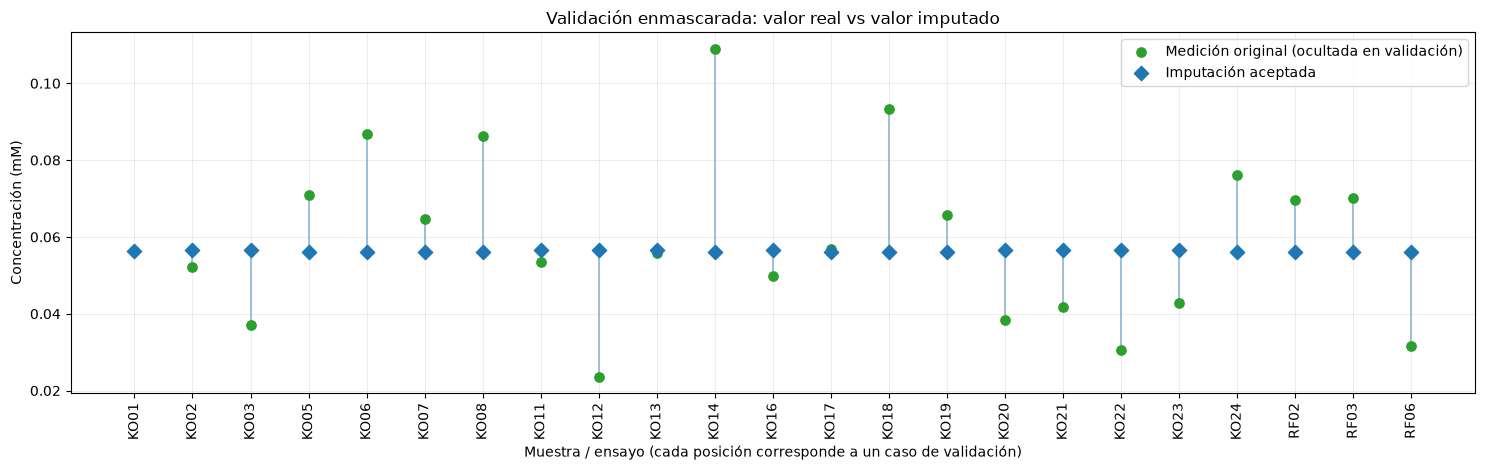

**Dispersión de validación:** la línea diagonal indica predicción perfecta.

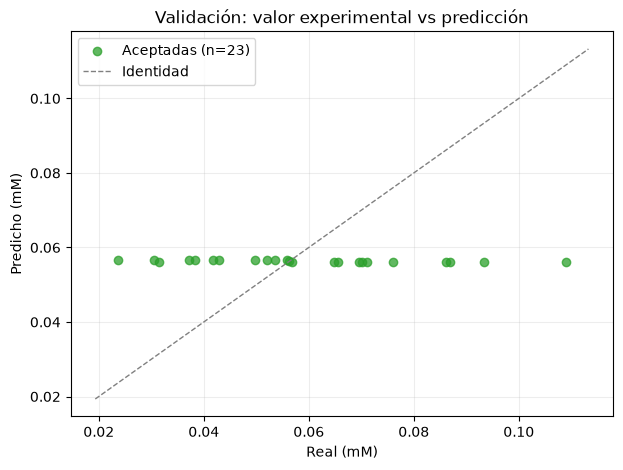

,trial_id,sample_id,truth_mM,estimate_mM,support,mechanism,aceptada
608,perturbation:KO01:fum[c],KO01,0.0563,0.05635,training_only,training_median,True
632,perturbation:KO02:fum[c],KO02,0.0521,0.05655,training_only,training_median,True
656,perturbation:KO03:fum[c],KO03,0.0372,0.05655,training_only,training_median,True
692,perturbation:KO05:fum[c],KO05,0.0710,0.05610,training_only,training_median,True
728,perturbation:KO06:fum[c],KO06,0.0869,0.05610,training_only,training_median,True
752,perturbation:KO07:fum[c],KO07,0.0648,0.05610,training_only,training_median,True
776,perturbation:KO08:fum[c],KO08,0.0862,0.05610,training_only,training_median,True
812,perturbation:KO11:fum[c],KO11,0.0536,0.05655,training_only,training_median,True
836,perturbation:KO12:fum[c],KO12,0.0236,0.05655,training_only,training_median,True
860,perturbation:KO13:fum[c],KO13,0.0559,0.05655,training_only,training_median,True


**Comparación estadística apareada sobre las mismas celdas evaluadas** (no incluye el resto de la matriz)

,Antes,Después,Cambio absoluto,Cambio (%)
n,23.00000,23.00000,0.00000,0.00000
media,0.05927,0.05631,-0.00296,-4.99230
mediana,0.05630,0.05610,-0.00020,-0.35524
s,0.02175,0.00022,-0.02152,-98.96881
varianza,0.00047,0.00000,-0.00047,-99.98937
Q1,0.04235,0.05610,0.01375,32.46753
Q3,0.07060,0.05655,-0.01405,-19.90085
IQR,0.02825,0.00045,-0.02780,-98.40708
min,0.02360,0.05610,0.03250,137.71186
max,0.10900,0.05655,-0.05245,-48.11927


### Análisis complementario: imputación de faltantes reales (sin verdad conocida)

23 mediciones originales · 7 imputaciones aceptadas · 0 faltantes pendientes.

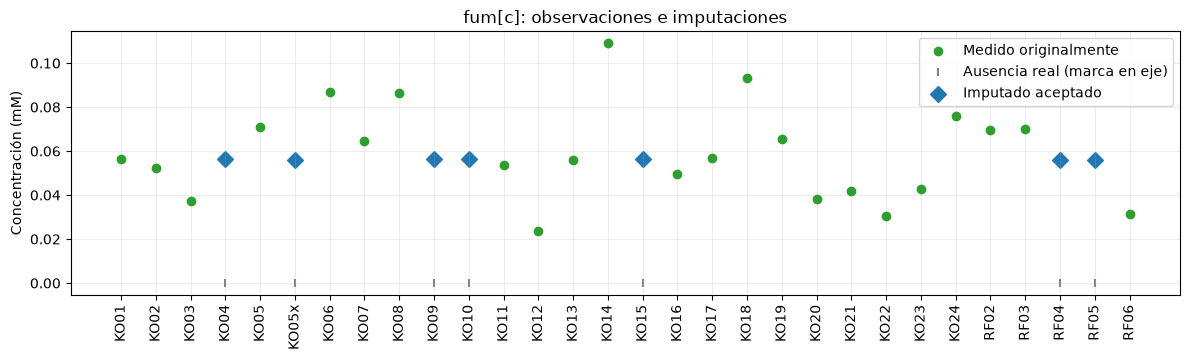

**Estadísticos antes vs después (Ishii, 30 muestras)**

,Antes,Después,Cambio absoluto,Cambio (%)
n,23.00000,30.00000,7.00000,30.43478
media,0.05927,0.05855,-0.00071,-1.20118
mediana,0.05630,0.05630,-0.00000,-0.00000
s,0.02175,0.01899,-0.00276,-12.69207
varianza,0.00047,0.00036,-0.00011,-23.77325
Q1,0.04235,0.05038,0.00802,18.94923
Q3,0.07060,0.06860,-0.00200,-2.83286
IQR,0.02825,0.01822,-0.01002,-35.48673
min,0.02360,0.02360,0.00000,0.00000
max,0.10900,0.10900,0.00000,0.00000


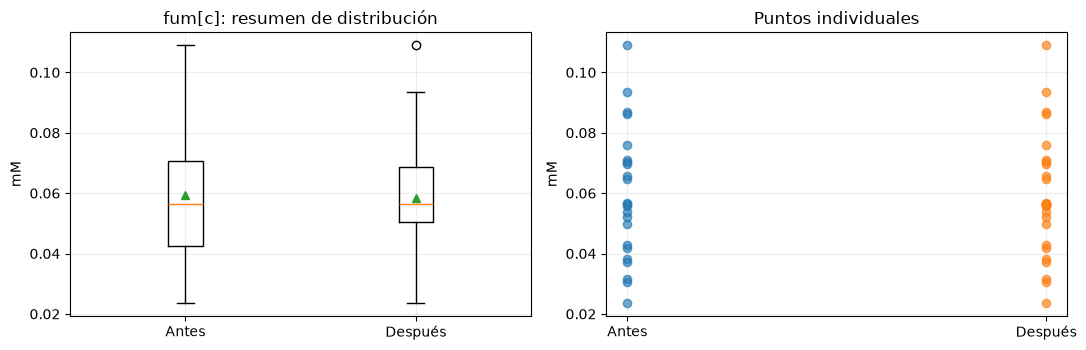

,sample_id,estimate_R,estimate_mM,support,mechanism,aceptada
38,KO04,0.102692,0.0563,training_only,training_median,True
40,KO05x,0.102327,0.0561,training_only,training_median,True
42,KO09,0.102692,0.0563,training_only,training_median,True
44,KO10,0.102692,0.0563,training_only,training_median,True
48,KO15,0.102692,0.0563,training_only,training_median,True
52,RF04,0.102327,0.0561,training_only,training_median,True
55,RF05,0.102327,0.0561,training_only,training_median,True


**Interpretación:** una menor varianza o IQR después de imputar no demuestra mayor precisión. Los valores reales ausentes son desconocidos; en validación sí hay valores experimentales de referencia.

In [5]:
POLITICA_ACTUAL='supported_plus_baseline'

def mostrar_panel(metabolito='fum', metodo='SimpleImputer', escenario='ishii', validacion='perturbation', politica='supported_plus_baseline', unidad='mM', ensayo='(Agregado)'):
    global POLITICA_ACTUAL
    POLITICA_ACTUAL=politica
    if metabolito not in METABOLITOS:
        raise ValueError(f'Metabolito no encontrado: {metabolito}. Opciones: {METABOLITOS}')
    if metodo not in METODOS or escenario not in ESCENARIOS or validacion not in EXPERIMENTOS or politica not in POLITICAS or unidad not in ('mM','R'):
        raise ValueError('Filtro desconocido')
    display(Markdown(f'### {metabolito} · {metodo} · {escenario} · {validacion}'))
    before=(ish_mM if unidad=='mM' else ish_R)[metabolito]
    display(Markdown('**Estadísticos de los datos originales medidos (Ishii)**'))
    display(descriptivos(before).to_frame('Antes').round(5))
    # Cada observación se cuenta por caso de validación, no como fila independiente de Ishii.
    v=pred[(pred.metabolite_id==metabolito)&(pred.method==metodo)&(pred.scenario==escenario)&(pred.experiment==validacion)].copy()
    v['ok']=aceptada(v,politica)
    truth='truth_mM' if unidad=='mM' else 'truth_R'
    estimate='estimate_mM' if unidad=='mM' else 'estimate_R'
    n=len(v); chosen=v.loc[v.ok & v[estimate].notna()].copy()
    mae=(chosen[estimate]-chosen[truth]).abs().mean() if len(chosen) else np.nan
    bias=(chosen[estimate]-chosen[truth]).mean() if len(chosen) else np.nan
    display(Markdown(f'**Validación:** {n} intentos · {len(chosen)} aceptados ({100*len(chosen)/n:.1f}% si n>0) · MAE={mae:.5g} {unidad} · sesgo={bias:.5g} {unidad}' if n else '**Sin ensayos para esta selección.**'))
    if len(v):
        display(Markdown('**Comparación principal: mediciones ocultadas artificialmente vs predicciones**. Cada punto verde y rombo azul corresponde al mismo caso; las líneas representan el error. Un caso sin predicción queda marcado.'))
        _comparacion_pareada_por_muestra(v,unidad,politica)
        display(Markdown('**Dispersión de validación:** la línea diagonal indica predicción perfecta.'))
        _scatter_validacion(v,unidad)
        display(v[['trial_id','sample_id',truth,estimate,'support','mechanism','ok']].rename(columns={'ok':'aceptada'}).head(25))
        # Comparación de distribuciones de verdades y estimaciones en exactamente las celdas aceptadas.
        if len(chosen):
            display(Markdown('**Comparación estadística apareada sobre las mismas celdas evaluadas** (no incluye el resto de la matriz)'))
            display(tabla_antes_despues(chosen[truth],chosen[estimate]).round(5))
    if ensayo!='(Agregado)':
        if ensayo not in set(v.trial_id):
            display(Markdown('El ensayo elegido no pertenece al conjunto filtrado.'))
        else:
            _ensayo_detalle(ensayo,metodo,escenario,unidad)

    mat, candidates, selected = matriz_real(metodo, escenario, politica)
    r=candidates[candidates.metabolite_id==metabolito].copy()
    r['ok']=aceptada(r,politica)
    actual=(mat if unidad=='mM' else mat.div(refs))[metabolito]
    display(Markdown('### Análisis complementario: imputación de faltantes reales (sin verdad conocida)'))
    display(Markdown(f'{int(before.notna().sum())} mediciones originales · {int((actual.notna() & before.isna()).sum())} imputaciones aceptadas · {int(actual.isna().sum())} faltantes pendientes.'))
    _puntos_por_muestra(metabolito,unidad,r)
    display(Markdown('**Estadísticos antes vs después (Ishii, 30 muestras)**'))
    display(tabla_antes_despues(before,actual).round(5))
    _plot_distribuciones(before,actual,metabolito,unidad)
    if len(r):
        cols=['sample_id','estimate_R','estimate_mM','support','mechanism','ok']
        display(r[cols].rename(columns={'ok':'aceptada'}))
    display(Markdown('**Interpretación:** una menor varianza o IQR después de imputar no demuestra mayor precisión. Los valores reales ausentes son desconocidos; en validación sí hay valores experimentales de referencia.'))

# Valores reales de metabolito se recuperan de archivos, sin asumir nombres abreviados.
METABOLITO_INICIAL = METABOLITOS[0]
EXPERIMENTO_INICIAL = 'perturbation' if 'perturbation' in EXPERIMENTOS else EXPERIMENTOS[0]
mostrar_panel(metabolito=METABOLITO_INICIAL,validacion=EXPERIMENTO_INICIAL)

### 3.2 · Controles interactivos

Cada modificación actualiza el análisis. El selector de ensayos se restringe a los correspondientes al metabolito, método, escenario y validación seleccionados.

In [ ]:
if WIDGETS_DISPONIBLES:
    met_w=widgets.Dropdown(options=METABOLITOS,value=METABOLITO_INICIAL,description='Metabolito',style={'description_width':'110px'})
    metodo_w=widgets.Dropdown(options=METODOS,value='SimpleImputer',description='Método',style={'description_width':'110px'})
    esc_w=widgets.Dropdown(options=[('Solo Ishii','ishii'),('Ishii + MMC2','ishii_mmc2')],value='ishii',description='Escenario',style={'description_width':'110px'})
    val_w=widgets.Dropdown(options=EXPERIMENTOS,value=EXPERIMENTO_INICIAL,description='Validación',style={'description_width':'110px'})
    pol_w=widgets.Dropdown(options=[('Todos los candidatos finitos','available'),('Soportados + mediana','supported_plus_baseline')],value='supported_plus_baseline',description='Política',style={'description_width':'110px'})
    uni_w=widgets.ToggleButtons(options=['mM','R'],value='mM',description='Unidad',style={'description_width':'110px'})
    trial_w=widgets.Dropdown(options=['(Agregado)'],description='Ensayo',style={'description_width':'110px'},layout=widgets.Layout(width='96%'))
    panel_out=widgets.Output()
    def opciones_ensayos(*_):
        x=pred[(pred.metabolite_id==met_w.value)&(pred.experiment==val_w.value)&(pred.method==metodo_w.value)&(pred.scenario==esc_w.value)]
        options=['(Agregado)']+sorted(x.trial_id.unique().tolist())
        trial_w.options=options
        trial_w.value='(Agregado)'
    def actualizar_panel(*_):
        with panel_out:
            clear_output(wait=True)
            mostrar_panel(met_w.value,metodo_w.value,esc_w.value,val_w.value,pol_w.value,uni_w.value,trial_w.value)
    for w in [met_w,metodo_w,esc_w,val_w]:w.observe(opciones_ensayos,names='value')
    for w in [met_w,metodo_w,esc_w,val_w,pol_w,uni_w,trial_w]:w.observe(actualizar_panel,names='value')
    opciones_ensayos()
    display(widgets.VBox([widgets.HBox([met_w,metodo_w]),widgets.HBox([esc_w,val_w]),widgets.HBox([pol_w,uni_w]),trial_w,panel_out]))
    actualizar_panel()
else:
    print('Falta ipywidgets. Instala ipywidgets o usa mostrar_panel(...) manualmente.')